# Car Sales Analytics Dashboard — Sprint 1: Data Preparation Pipeline
## Team 10 | Y3 Term 1 Project Management
**Team Members:**
- **Scrum Master:** Chhoun Vannak Sok Panha
- **Lead Developer:** Samolty Lundy
- **Product Owner:** Por Menghong

---

### Sprint 1 Overview & Scope
**Sprint Duration:** 19 Oct – 02 Nov  
**Sprint Goal:** Obtain, profile, assess data quality, clean, and transform the raw car sales dataset into a validated, high-integrity analytical data store ready for downstream SQL exploration (Sprint 2) and Power BI delivery (Sprint 3).

| Jira Ticket | Epic | Description | Story Points | Status |
| :--- | :--- | :--- | :---: | :---: |
| **CDS-64** | Data Collection | Acquire, inspect provenance, and load raw car sales records | 2 SP | Complete |
| **CDS-65** | Data Understanding | Profile schema, variable types, distributions, and domain semantics | 3 SP | Complete |
| **CDS-66** | Data Quality | Assess missing data, statistical outliers (IQR, Z-score), and duplicates | 5 SP | Complete |
| **CDS-67** | Data Cleaning | Impute missing values and filter erroneous domain-impossible records | 8 SP | Complete |
| **CDS-68** | Data Transformation | Retain core BI dimensions, drop noise artifacts, and export clean CSV | 5 SP | Complete |
| **Total** | | | **23 SP** | **Ready for Review** |


## 1. Data Collection & Intake Verification (`CDS-64`)

### Task: Load and verify the raw car sales dataset

**Dataset Provenance:**
The raw dataset originates from the Indian automotive marketplace **CarDekho.com**, containing historical used-car listings across major metropolitan regions. It records comprehensive vehicle specifications, seller information, and actual market transaction asking prices.

**Repository Intake Path:** `raw/cardekho_raw.csv`  
**Expected Dimensions:** 15,244 listings across 25 features.


In [1]:
# Import required data science and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# Suppress minor visual warnings
warnings.filterwarnings('ignore')

# Set professional plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.autolayout'] = False

# Robust relative path resolution (works from root or subfolders)
raw_path = 'raw/cardekho_raw.csv'
if not os.path.exists(raw_path):
    raw_path = '../raw/cardekho_raw.csv'

# Load the raw dataset
df = pd.read_csv(raw_path)

print(f"Dataset successfully loaded from: {raw_path}")
print(f"Dataset Dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns")


Dataset successfully loaded from: raw/cardekho_raw.csv
Dataset Dimensions: 15,244 rows and 25 columns


## 2. Data Understanding & Profiling (`CDS-65`)

### Dataset Structure & Unit of Observation
- **Unit of Observation:** Each row represents a single unique used car listing posted for sale.
- **Key Dimension Categories:**
  1. **Vehicle Identity & Classification:** `car_name`, `brand`, `model`, `model_grouped`, `brand_tier`, `real_body_type`, `real_common_trim`.
  2. **Technical Specifications:** `engine` (CC), `max_power` (bhp), `mileage` (km/l or km/kg), `seats`, `transmission_type`, `fuel_type`.
  3. **Usage & History:** `vehicle_age` (years), `km_driven` (odometer reading), `km_per_year`, `seller_type`, `real_typical_owner_type`, `real_avg_owner_count`.
  4. **Pricing & Valuation:** `selling_price` (actual used car asking price in INR), `real_new_ex_showroom_price` (brand-new showroom baseline in INR Lakhs).
  5. **Geographical & Operational:** `real_primary_city`.
  6. **Technical Merging Flags:** `matched_dt`, `matched_eng`, `real_model_variant_count`.

---

### Variable Classification Dictionary

| Feature Name | Primary Type | Sub-Type | Description |
| :--- | :--- | :--- | :--- |
| `selling_price` | Numerical | Continuous | Used vehicle asking price in INR (Target Variable) |
| `vehicle_age` | Numerical | Discrete | Age of the vehicle in years |
| `km_driven` | Numerical | Continuous | Total distance driven in kilometers |
| `km_per_year` | Numerical | Continuous | Annual usage rate (`km_driven / vehicle_age`) |
| `mileage` | Numerical | Continuous | Fuel efficiency (km/litre or km/kg) |
| `engine` | Numerical | Discrete | Engine displacement capacity in CC |
| `max_power` | Numerical | Continuous | Maximum power output in brake horsepower (bhp) |
| `seats` | Numerical | Discrete | Passenger seating capacity (2, 4, 5, 6, 7, 8, 9) |
| `real_new_ex_showroom_price` | Numerical | Continuous | Original brand-new ex-showroom price benchmark |
| `real_avg_owner_count` | Numerical | Continuous / Discrete | Average historical owners for model variant |
| `brand` | Categorical | Nominal | Vehicle manufacturer (e.g., Maruti, Hyundai, BMW) |
| `model` | Categorical | Nominal | Specific car model name (e.g., Swift, City, Creta) |
| `fuel_type` | Categorical | Nominal | Fuel category (Petrol, Diesel, CNG, LPG, Electric) |
| `seller_type` | Categorical | Nominal | Seller category (Individual, Dealer, Trustmark Dealer) |
| `transmission_type` | Categorical | Nominal | Transmission mechanism (Manual, Automatic) |
| `real_body_type` | Categorical | Nominal | Vehicle segment (Hatchback, Sedan, SUV, MUV, etc.) |
| `real_primary_city` | Categorical | Nominal | Primary city / market location in India |
| `brand_tier` | Categorical | Ordinal | Brand prestige tier (Budget, Mid, Luxury) |


In [2]:
# Inspect column types and initial memory usage
print("=== Dataset Summary Info ===")
df.info()

print("\n=== First 3 Records ===")
display(df.head(3))


=== Dataset Summary Info ===
<class 'pandas.DataFrame'>
RangeIndex: 15244 entries, 0 to 15243
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   car_name                    15244 non-null  str    
 1   brand                       15244 non-null  str    
 2   model                       15244 non-null  str    
 3   vehicle_age                 15244 non-null  int64  
 4   km_driven                   15244 non-null  int64  
 5   seller_type                 15244 non-null  str    
 6   fuel_type                   15244 non-null  str    
 7   transmission_type           15244 non-null  str    
 8   mileage                     15244 non-null  float64
 9   engine                      15244 non-null  int64  
 10  max_power                   15244 non-null  float64
 11  seats                       15244 non-null  int64  
 12  selling_price               15244 non-null  int64  
 13  real_primary_

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,real_avg_owner_count,real_model_variant_count,real_common_trim,matched_dt,real_new_ex_showroom_price,real_body_type,matched_eng,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.7,796,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,13333.33,Economy,Alto
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.9,1197,...,1.08,25.0,i10 Sportz,1.0,0.641574,Hatchback,1.0,4000.00,Economy,Grand
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.0,1197,...,1.18,67.0,1.2 Magna,1.0,0.820343,Hatchback,1.0,5454.55,Economy,i20


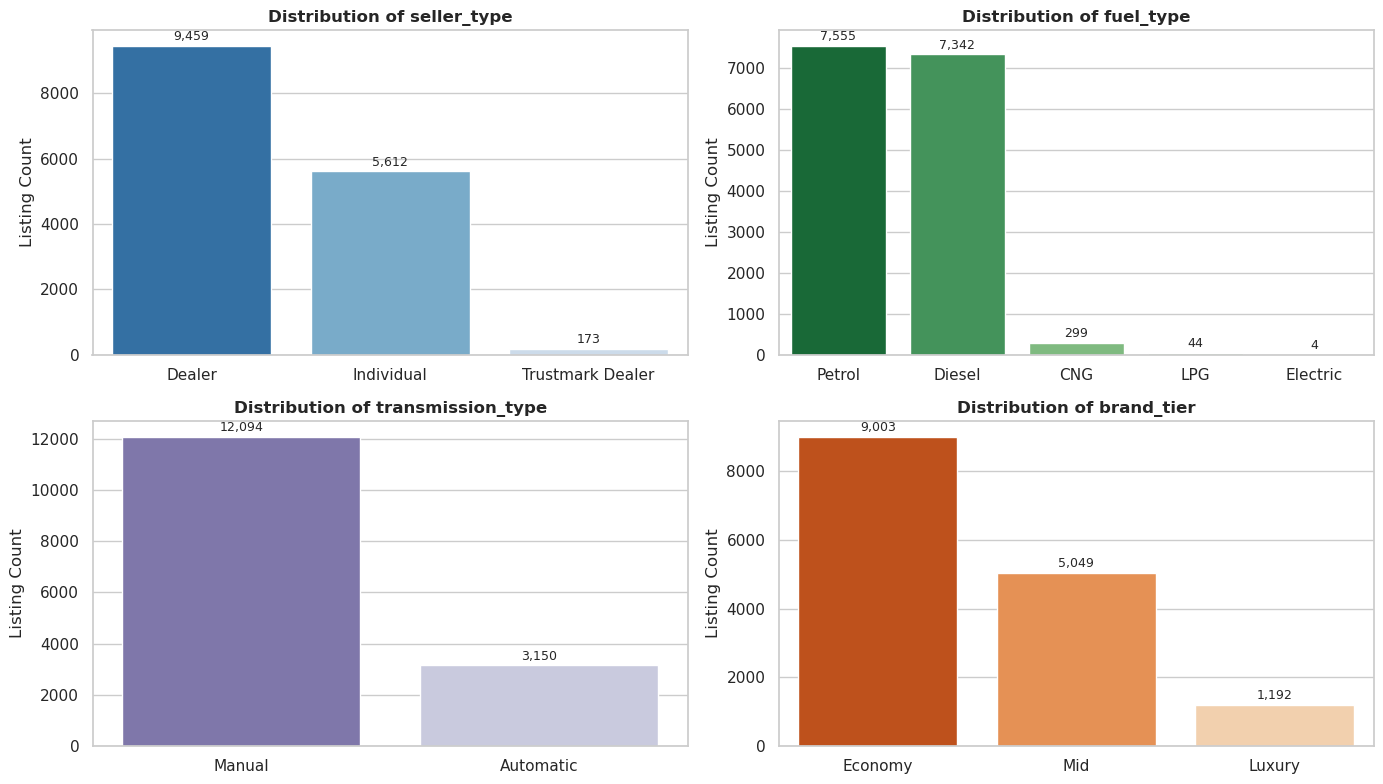

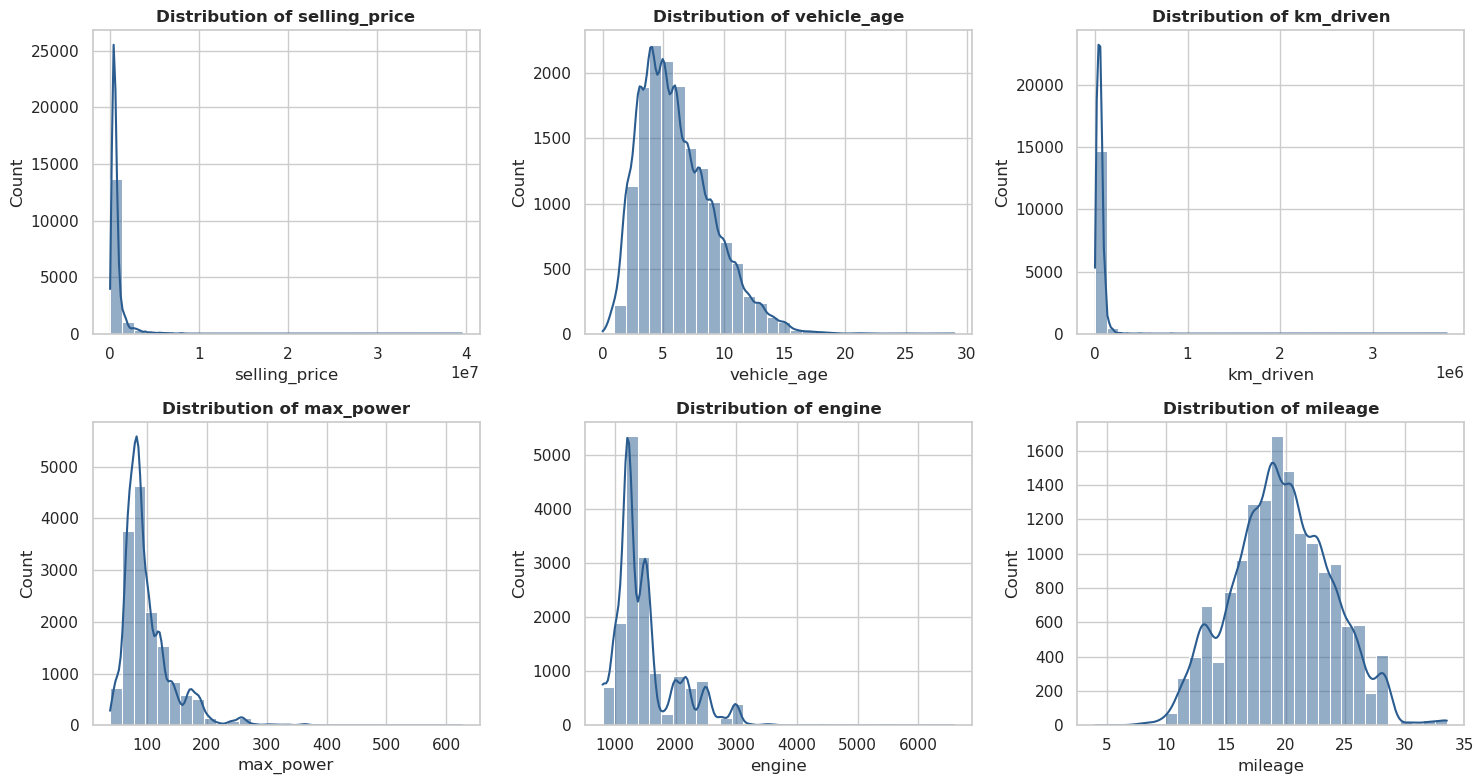

In [3]:
# 1. Visualize distributions of core categorical business dimensions
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

cat_cols = ['seller_type', 'fuel_type', 'transmission_type', 'brand_tier']
palettes = ['Blues_r', 'Greens_r', 'Purples_r', 'Oranges_r']

for ax, col, pal in zip(axes.flatten(), cat_cols, palettes):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, palette=pal, ax=ax)
    ax.set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Listing Count')
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

# 2. Visualize distributions of core continuous numerical features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_nums = ['selling_price', 'vehicle_age', 'km_driven', 'max_power', 'engine', 'mileage']

for ax, num_col in zip(axes.flatten(), key_nums):
    sns.histplot(df[num_col], kde=True, bins=30, color='#2b5c8f', ax=ax)
    ax.set_title(f'Distribution of {num_col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(num_col)

plt.tight_layout()
plt.show()


## 3. Data Quality Assessment (`CDS-66`)

### Data Quality Dimensions Evaluated:
1. **Completeness:** Identification and quantification of missing values.
2. **Uniqueness:** Detection of exact duplicate records.
3. **Validity & Plausibility:** Statistical outlier detection using both **IQR (Interquartile Range)** and **Z-score** methods, paired with domain-specific sanity checks.


=== Missing Data Audit Report ===


,Missing Count,Percentage (%)
matched_eng,5320,34.90
real_new_ex_showroom_price,5320,34.90
real_avg_owner_count,304,1.99
matched_dt,304,1.99
real_model_variant_count,304,1.99


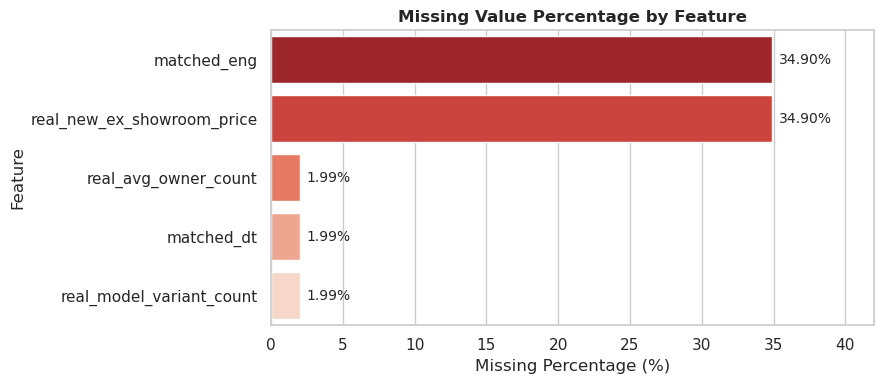

In [4]:
# Audit missing values across all features
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_pct.round(2)
})

# Filter only columns containing null values
null_report = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
print("=== Missing Data Audit Report ===")
display(null_report)

# Visualize missing percentages
if not null_report.empty:
    plt.figure(figsize=(9, 4))
    ax = sns.barplot(
        data=null_report.reset_index(),
        x='Percentage (%)',
        y='index',
        palette='Reds_r'
    )
    plt.title('Missing Value Percentage by Feature', fontsize=12, fontweight='bold')
    plt.xlabel('Missing Percentage (%)')
    plt.ylabel('Feature')
    for p in ax.patches:
        width = p.get_width()
        ax.annotate(f'{width:.2f}%', (width + 0.5, p.get_y() + p.get_height() / 2.),
                    va='center', fontsize=10)
    plt.xlim(0, 42)
    plt.tight_layout()
    plt.show()


=== Statistical Outlier Audit Summary ===


,IQR Flagged Count,Z-score Flagged (|z|>3)
vehicle_age,154,64
km_driven,464,77
mileage,87,57
engine,2103,67
max_power,853,297
seats,2475,372
selling_price,1371,287
real_avg_owner_count,314,182
real_model_variant_count,0,0
matched_dt,0,0


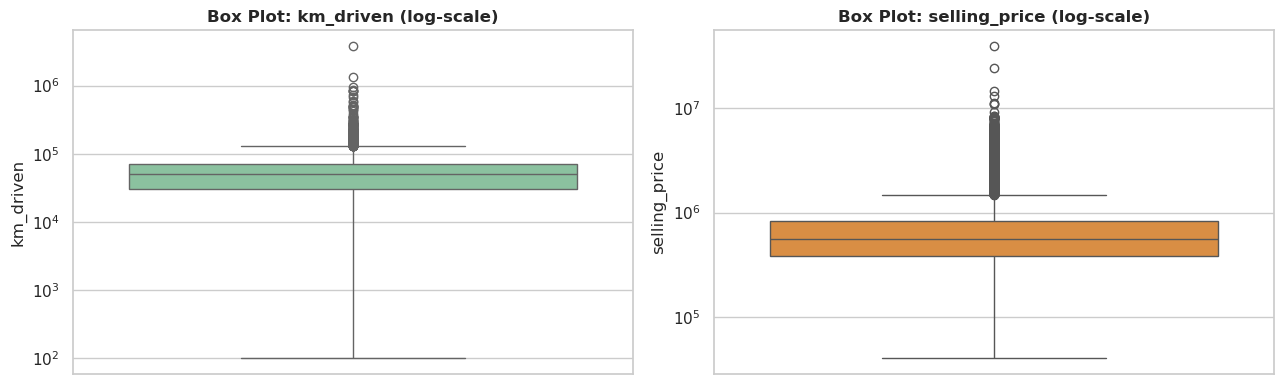

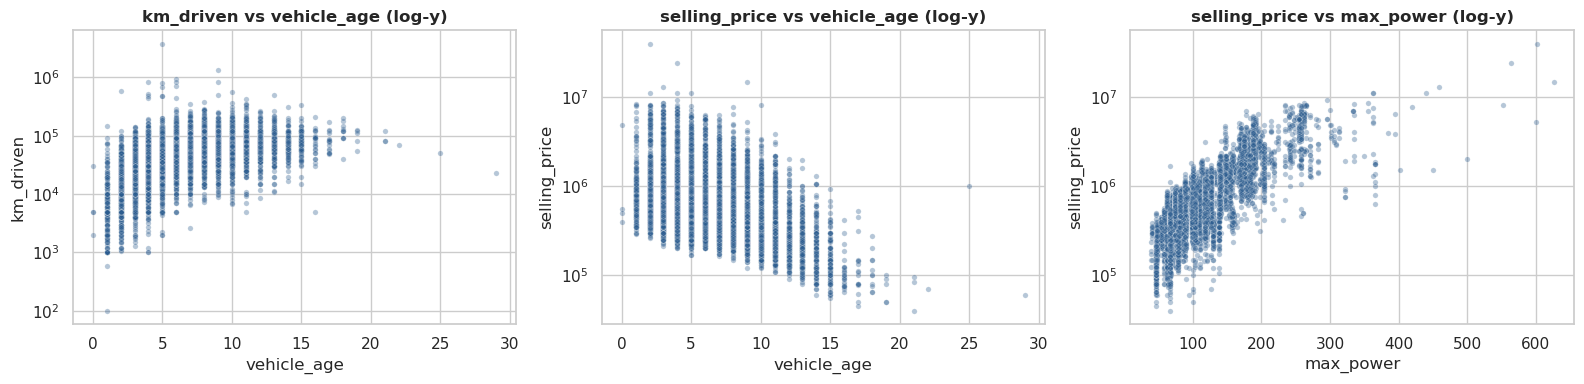

In [5]:
# Audit numerical columns for statistical outliers
numerical_cols = df.select_dtypes(include=[np.number]).columns

# 1. IQR Method (1.5 * IQR)
q1 = df[numerical_cols].quantile(0.25)
q3 = df[numerical_cols].quantile(0.75)
iqr = q3 - q1
outliers_iqr = ((df[numerical_cols] < (q1 - 1.5 * iqr)) | (df[numerical_cols] > (q3 + 1.5 * iqr))).sum()

# 2. Z-Score Method (|z| > 3)
z_scores = (df[numerical_cols] - df[numerical_cols].mean()) / df[numerical_cols].std()
outliers_z = (np.abs(z_scores) > 3).sum()

outlier_audit = pd.DataFrame({
    'IQR Flagged Count': outliers_iqr,
    'Z-score Flagged (|z|>3)': outliers_z
})
print("=== Statistical Outlier Audit Summary ===")
display(outlier_audit)

# 3. Log-scale box plots for heavy-tailed pricing and distance distributions
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(y=df["km_driven"], ax=ax[0], color='#82ca9d')
ax[0].set_yscale("log")
ax[0].set_title("Box Plot: km_driven (log-scale)", fontweight='bold')

sns.boxplot(y=df["selling_price"], ax=ax[1], color='#f28e2b')
ax[1].set_yscale("log")
ax[1].set_title("Box Plot: selling_price (log-scale)", fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Multi-dimensional scatter plots to inspect anomalies
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pairs = [("vehicle_age", "km_driven"), ("vehicle_age", "selling_price"), ("max_power", "selling_price")]
for a, (x, y) in zip(ax, pairs):
    sns.scatterplot(data=df, x=x, y=y, s=15, alpha=0.35, ax=a, color='#2b5c8f')
    a.set_yscale("log")
    a.set_title(f"{y} vs {x} (log-y)", fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Data Cleaning Decisions & Anomaly Treatment (`CDS-67`)

### Domain-Driven Cleaning Decisions:
1. **Legitimate Market Outliers RETAINED:**
   - Extreme high values in `selling_price` (> 10,000,000 INR), `max_power` (> 400 bhp), and `engine` (> 4,000 CC) represent genuine supercars/luxury models (Ferrari, Bentley, Porsche, Rolls-Royce). Removing them would truncate valid automotive market variance.
   - Values in `seats` (6, 7, 8, 9) represent legitimate multi-passenger MPVs/SUVs (Toyota Innova, Mahindra Scorpio).
2. **Impossible Usage Anomalies DROPPED:**
   - Calculating annual distance driven (`km_per_year = km_driven / vehicle_age`) reveals 13 records with $> 100,000$ km/year (e.g. a 5-year-old car recorded with 3,800,000 km, or 2,000 km every single day). These represent severe clerical data entry errors (extra zeros).
   - **Action:** Safely filter out these 13 invalid listings.
3. **Missing Value Imputation:**
   - `real_avg_owner_count` (~1.99% missing): Imputed using the **median** (robust to right skew).
   - `real_new_ex_showroom_price` (~34.90% missing): Imputed hierarchically using the **brand-level median**, falling back to the **brand tier median**, then overall median. This preserves brand pricing boundaries rather than assigning economy car showroom prices to luxury models.


In [6]:
# Create an independent working copy
df_clean = df.copy()
initial_rows = len(df_clean)

# 1. Filter out impossible annual usage outliers (> 100,000 km/year)
km_per_year_chk = df_clean["km_driven"] / df_clean["vehicle_age"].clip(lower=1)
impossible_km_mask = km_per_year_chk > 100_000

print(f"Flagged {impossible_km_mask.sum()} physically impossible km_driven entries.")
display(df_clean.loc[impossible_km_mask, ["car_name", "brand", "model", "vehicle_age", "km_driven"]]
        .assign(km_per_year=km_per_year_chk[impossible_km_mask])
        .sort_values(by="km_per_year", ascending=False))

df_clean = df_clean.loc[~impossible_km_mask].reset_index(drop=True)
print(f"Row count after removing impossible records: {initial_rows:,} -> {len(df_clean):,}")

# 2. Impute real_avg_owner_count using median
median_owner = df_clean['real_avg_owner_count'].median()
df_clean['real_avg_owner_count'] = df_clean['real_avg_owner_count'].fillna(median_owner)
print(f"Imputed 'real_avg_owner_count' missing values with median: {median_owner:.2f}")

# 3. Impute real_new_ex_showroom_price hierarchically (Brand -> Brand Tier -> Overall Median)
brand_medians = df_clean.groupby('brand')['real_new_ex_showroom_price'].transform('median')
tier_medians = df_clean.groupby('brand_tier')['real_new_ex_showroom_price'].transform('median')
overall_median = df_clean['real_new_ex_showroom_price'].median()

df_clean['real_new_ex_showroom_price'] = (
    df_clean['real_new_ex_showroom_price']
    .fillna(brand_medians)
    .fillna(tier_medians)
    .fillna(overall_median)
)
print("Imputed 'real_new_ex_showroom_price' using brand-tier hierarchical medians.")

# Verify completeness of clean working copy
print(f"Remaining null values in key numerical features: {df_clean[['real_avg_owner_count', 'real_new_ex_showroom_price']].isnull().sum().to_dict()}")


Flagged 13 physically impossible km_driven entries.


,car_name,brand,model,vehicle_age,km_driven,km_per_year
15242,Mahindra XUV500,Mahindra,XUV500,5,3800000,760000.000000
7486,Toyota Fortuner,Toyota,Fortuner,2,590000,295000.000000
4516,Renault Duster,Renault,Duster,4,850000,212500.000000
11508,Volkswagen Polo,Volkswagen,Polo,5,820000,164000.000000
8701,Toyota Innova,Toyota,Innova,6,950000,158333.333333
12210,Renault Duster,Renault,Duster,1,150000,150000.000000
11790,Mercedes-Benz E-Class,Mercedes-Benz,E-Class,9,1325000,147222.222222
10742,Hyundai Creta,Hyundai,Creta,6,825000,137500.000000
9089,Skoda Rapid,Skoda,Rapid,5,675000,135000.000000
10296,Honda Jazz,Honda,Jazz,4,525000,131250.000000


Row count after removing impossible records: 15,244 -> 15,231
Imputed 'real_avg_owner_count' missing values with median: 1.15
Imputed 'real_new_ex_showroom_price' using brand-tier hierarchical medians.
Remaining null values in key numerical features: {'real_avg_owner_count': 0, 'real_new_ex_showroom_price': 0}


## 5. Data Transformation & Export (`CDS-68`)

### Critical Feature Retention Strategy for Sprints 2 & 3:
In an end-to-end analytics project that culminates in a **Power BI Management Dashboard (Sprint 3)**, data cleaning must **NOT** prematurely eliminate core business dimensions.

- **RETAINED for Business Analysis & Dashboard Slicers:**
  - `brand` & `model`: Essential for vehicle make/model comparison, pricing tier analysis, and user slicers.
  - `fuel_type`: Fundamental dealership inventory category (Petrol vs Diesel vs CNG vs EV).
  - `seats`: Critical for filtering passenger cars vs multi-passenger family/commercial vehicles.
  - `real_primary_city`: Key regional dimension for geographic dealership performance and inventory reallocation.
  - `seller_type` & `transmission_type`: Essential market segmentation attributes.
  - `brand_tier` & `real_body_type`: Core high-level categorical grouping dimensions.
- **PRUNED (Technical Scraping Artifacts Only):**
  - `matched_dt` & `matched_eng`: Redundant single-value matching flags (`1.0`) with zero analytical information gain.
  - `real_model_variant_count`: Internal scraper counter artifact.


In [7]:
# Define uninformative technical scrape flags to drop
prune_cols = ['matched_dt', 'matched_eng', 'real_model_variant_count']
df_clean = df_clean.drop(columns=prune_cols)
print(f"Dropped {len(prune_cols)} technical artifacts: {prune_cols}")

# Standardize string columns (strip trailing whitespace)
string_cols = df_clean.select_dtypes(include='object').columns
for sc in string_cols:
    df_clean[sc] = df_clean[sc].astype(str).str.strip()

# Check and resolve duplicate rows
exact_dupes = df_clean.duplicated().sum()
print(f"Exact duplicate records found: {exact_dupes}")
if exact_dupes > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print("Exact duplicates successfully removed.")

# Ensure export directory exists
export_dir = 'cleaned_data' if os.path.exists('cleaned_data') else '../cleaned_data'
os.makedirs(export_dir, exist_ok=True)
export_path = os.path.join(export_dir, 'cleaned.csv')

# Export clean, production-ready dataset
df_clean.to_csv(export_path, index=False)

print("=" * 60)
print("FINAL CLEANED DATASET AUDIT (SPRINT 1)")
print("=" * 60)
print(f"Destination:          {export_path}")
print(f"Final Shape:          {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print(f"Total Missing Values: {df_clean.isnull().sum().sum()}")
print(f"Total Duplicate Rows: {df_clean.duplicated().sum()}")
print("=" * 60)
print(f"\nRetained Feature Columns ({len(df_clean.columns)}):")
print(df_clean.columns.tolist())

# Preview first 5 rows of final cleaned data
display(df_clean.head(5))


Dropped 3 technical artifacts: ['matched_dt', 'matched_eng', 'real_model_variant_count']
Exact duplicate records found: 0


FINAL CLEANED DATASET AUDIT (SPRINT 1)
Destination:          cleaned_data/cleaned.csv
Final Shape:          15,231 rows, 22 columns
Total Missing Values: 0
Total Duplicate Rows: 0

Retained Feature Columns (22):
['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price', 'real_primary_city', 'real_typical_owner_type', 'real_avg_owner_count', 'real_common_trim', 'real_new_ex_showroom_price', 'real_body_type', 'km_per_year', 'brand_tier', 'model_grouped']


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,selling_price,real_primary_city,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,...,120000,Hyderabad,First,1.15,LXi,0.641574,Unknown,13333.33,Economy,Alto
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,...,550000,Coimbatore,First,1.08,i10 Sportz,0.641574,Hatchback,4000.00,Economy,Grand
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,...,215000,Kochi,First,1.18,1.2 Magna,0.820343,Hatchback,5454.55,Economy,i20
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,...,226000,Hyderabad,First,1.15,LXi,0.641574,Unknown,4111.11,Economy,Alto
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,...,570000,Mumbai,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,5000.00,Mid,Ecosport


## 6. Sprint 1 Definition of Done (DoD) Verification

### Sprint Review Sign-Off Checklist:
- [x] **Reproducible Ingestion (`CDS-64`):** Raw dataset loaded reliably from `raw/cardekho_raw.csv` with full provenance documented.
- [x] **Exploratory Profiling (`CDS-65`):** Variable types, unit of observation, distributions, and domain semantics thoroughly documented.
- [x] **Quality Assessment (`CDS-66`):** Missing values quantified; statistical outliers inspected using IQR and Z-scores.
- [x] **Domain Cleaning (`CDS-67`):** 13 impossible odometer entries filtered; missing values imputed with hierarchical business logic; luxury cars retained.
- [x] **Transformation & Handover (`CDS-68`):** Preserved 22 high-value business features (`brand`, `fuel_type`, `seats`, `city`, etc.); exported zero-missing, zero-duplicate dataset to `cleaned_data/cleaned.csv`.
- [x] **Sprint 2 Readiness:** Cleaned dataset is 100% prepared for SQL queries and exploratory business insights.

---
*Sprint 1 approved and ready for Product Owner (Por Menghong) sign-off and Sprint 2 planning.*
